# NMS Tutorial

## NMS 알고리즘

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Detected boxes:
Box 1: (100, 100) - (200, 200), score: 0.90
Box 2: (110, 110) - (210, 210), score: 0.80
Box 3: (300, 300) - (400, 400), score: 0.70
Box 4: (105, 105) - (205, 205), score: 0.60

Score order: [0 1 2 3] (indices)
Score values: [0.9 0.8 0.7 0.6]

Selected box: 0 (score: 0.90)

NMS Process:
Keep Box1 (score: 0.90)
  Remove Box2 (IoU with Box1: 0.681 > 0.5)
  Keep Box3 (IoU with Box1: 0.000 <= 0.5)
  Remove Box4 (IoU with Box1: 0.822 > 0.5)
Keep Box3 (score: 0.70)


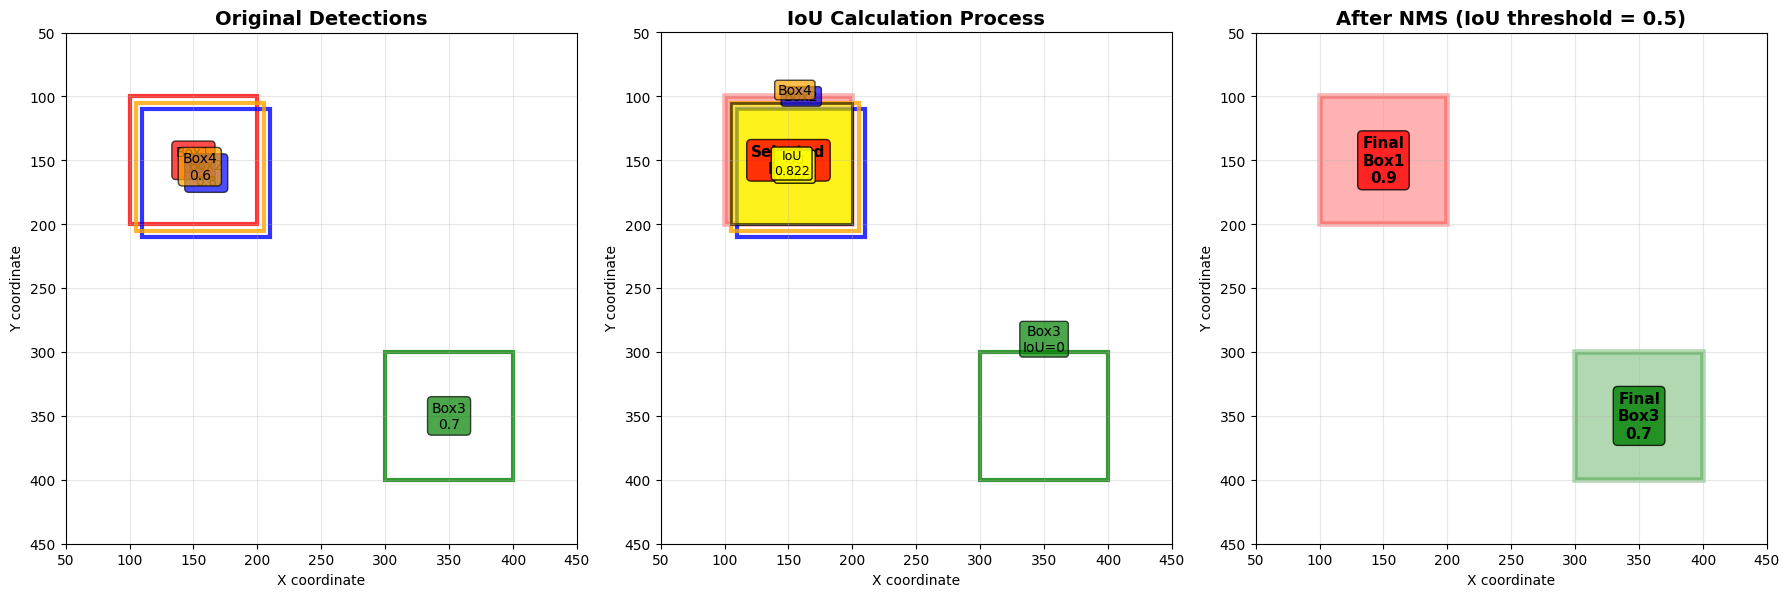


Final Result:
Boxes kept after NMS: ['Box1', 'Box3']
Boxes removed: ['Box2', 'Box4']


In [2]:
# Non-Maximum Suppression (NMS) 알고리즘
import matplotlib.patches as patches

def nms_demo_visual():
    """NumPy operations used in NMS algorithm with visualization"""
    
    # 가상의 검출 결과들 (x1, y1, x2, y2, score)
    detections = np.array([
        [100, 100, 200, 200, 0.9],  # Box 1 (높은 점수)
        [110, 110, 210, 210, 0.8],  # Box 2 (Box 1과 겹침)
        [300, 300, 400, 400, 0.7],  # Box 3 (독립적)
        [105, 105, 205, 205, 0.6],  # Box 4 (Box 1과 많이 겹침)
    ])
    
    # 박스 색상 정의
    colors = ['red', 'blue', 'green', 'orange']
    
    print("Detected boxes:")
    for i, det in enumerate(detections):
        print(f"Box {i+1}: ({det[0]:.0f}, {det[1]:.0f}) - ({det[2]:.0f}, {det[3]:.0f}), score: {det[4]:.2f}")
    
    # 원본 박스들 시각화
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # 1. 원본 검출 결과
    ax1 = axes[0]
    ax1.set_xlim(50, 450)
    ax1.set_ylim(50, 450)
    ax1.set_aspect('equal')
    ax1.set_title('Original Detections', fontsize=14, fontweight='bold')
    ax1.invert_yaxis()  # y축 뒤집기 (이미지 좌표계)
    
    for i, (x1, y1, x2, y2, score) in enumerate(detections):
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, 
                               linewidth=3, edgecolor=colors[i], 
                               facecolor='none', alpha=0.8)
        ax1.add_patch(rect)
        # 박스 중심에 점수 표시
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        ax1.text(cx, cy, f'Box{i+1}\n{score:.1f}', 
                ha='center', va='center', fontsize=10, 
                bbox=dict(boxstyle='round,pad=0.3', facecolor=colors[i], alpha=0.7))
    
    ax1.grid(True, alpha=0.3)
    ax1.set_xlabel('X coordinate')
    ax1.set_ylabel('Y coordinate')
    
    x1, y1, x2, y2, scores = detections[:, 0], detections[:, 1], detections[:, 2], detections[:, 3], detections[:, 4]
    
    # score가 높은 순서로 정렬
    idxs = scores.argsort()[::-1]
    print(f"\nScore order: {idxs} (indices)")
    print(f"Score values: {scores[idxs]}")
    
    # 2. IoU 계산 과정 시각화
    ax2 = axes[1]
    ax2.set_xlim(50, 450)
    ax2.set_ylim(50, 450)
    ax2.set_aspect('equal')
    ax2.set_title('IoU Calculation Process', fontsize=14, fontweight='bold')
    ax2.invert_yaxis()
    
    # 첫 번째 박스(가장 높은 score)와 나머지 박스들 간의 IoU 계산
    selected_idx = idxs[0]  # 가장 높은 score의 박스
    print(f"\nSelected box: {selected_idx} (score: {scores[selected_idx]:.2f})")
    
    # 선택된 박스 강조 표시
    sel_x1, sel_y1, sel_x2, sel_y2 = detections[selected_idx][:4]
    selected_rect = patches.Rectangle((sel_x1, sel_y1), sel_x2-sel_x1, sel_y2-sel_y1,
                                    linewidth=4, edgecolor='red', facecolor='red', alpha=0.3)
    ax2.add_patch(selected_rect)
    ax2.text((sel_x1+sel_x2)/2, (sel_y1+sel_y2)/2, f'Selected\nBox{selected_idx+1}', 
            ha='center', va='center', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='red', alpha=0.8))
    
    # 다른 박스들과의 IoU 계산 및 시각화
    for j, other_idx in enumerate(idxs[1:]):
        other_x1, other_y1, other_x2, other_y2 = detections[other_idx][:4]
        
        # 교집합 계산
        xx1 = max(sel_x1, other_x1)
        yy1 = max(sel_y1, other_y1)
        xx2 = min(sel_x2, other_x2)
        yy2 = min(sel_y2, other_y2)
        
        # 교집합이 존재하는 경우
        if xx1 < xx2 and yy1 < yy2:
            inter_w = xx2 - xx1
            inter_h = yy2 - yy1
            inter_area = inter_w * inter_h
            
            # 합집합 계산
            area1 = (sel_x2 - sel_x1) * (sel_y2 - sel_y1)
            area2 = (other_x2 - other_x1) * (other_y2 - other_y1)
            union_area = area1 + area2 - inter_area
            
            # IoU 계산
            iou = inter_area / (union_area + 1e-6)
            
            # 다른 박스 그리기
            other_rect = patches.Rectangle((other_x1, other_y1), other_x2-other_x1, other_y2-other_y1,
                                         linewidth=3, edgecolor=colors[other_idx], 
                                         facecolor='none', alpha=0.8)
            ax2.add_patch(other_rect)
            
            # 교집합 영역 강조
            if inter_area > 0:
                inter_rect = patches.Rectangle((xx1, yy1), inter_w, inter_h,
                                             linewidth=2, edgecolor='black', 
                                             facecolor='yellow', alpha=0.6)
                ax2.add_patch(inter_rect)
                ax2.text((xx1+xx2)/2, (yy1+yy2)/2, f'IoU\n{iou:.3f}', 
                        ha='center', va='center', fontsize=9,
                        bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.9))
            
            # 박스 레이블
            ax2.text((other_x1+other_x2)/2, other_y1-10, f'Box{other_idx+1}', 
                    ha='center', va='center', fontsize=10,
                    bbox=dict(boxstyle='round,pad=0.2', facecolor=colors[other_idx], alpha=0.7))
        
        else:
            # 교집합이 없는 경우
            other_rect = patches.Rectangle((other_x1, other_y1), other_x2-other_x1, other_y2-other_y1,
                                         linewidth=3, edgecolor=colors[other_idx], 
                                         facecolor='none', alpha=0.8)
            ax2.add_patch(other_rect)
            ax2.text((other_x1+other_x2)/2, other_y1-10, f'Box{other_idx+1}\nIoU=0', 
                    ha='center', va='center', fontsize=10,
                    bbox=dict(boxstyle='round,pad=0.2', facecolor=colors[other_idx], alpha=0.7))
    
    ax2.grid(True, alpha=0.3)
    ax2.set_xlabel('X coordinate')
    ax2.set_ylabel('Y coordinate')
    
    # 3. NMS 결과 시각화
    ax3 = axes[2]
    ax3.set_xlim(50, 450)
    ax3.set_ylim(50, 450)
    ax3.set_aspect('equal')
    ax3.set_title('After NMS (IoU threshold = 0.5)', fontsize=14, fontweight='bold')
    ax3.invert_yaxis()
    
    # NMS 알고리즘 적용
    keep = []
    remaining_idxs = idxs.copy()
    iou_threshold = 0.5
    
    print(f"\nNMS Process:")
    while len(remaining_idxs) > 0:
        # 가장 높은 점수의 박스 선택
        current = remaining_idxs[0]
        keep.append(current)
        print(f"Keep Box{current+1} (score: {scores[current]:.2f})")
        
        if len(remaining_idxs) == 1:
            break
            
        # 현재 박스와 나머지 박스들 간의 IoU 계산
        curr_x1, curr_y1, curr_x2, curr_y2 = detections[current][:4]
        
        new_remaining = [current]  # 현재 박스는 제외
        for other in remaining_idxs[1:]:
            other_x1, other_y1, other_x2, other_y2 = detections[other][:4]
            
            # IoU 계산
            xx1 = max(curr_x1, other_x1)
            yy1 = max(curr_y1, other_y1)
            xx2 = min(curr_x2, other_x2)
            yy2 = min(curr_y2, other_y2)
            
            if xx1 < xx2 and yy1 < yy2:
                inter_area = (xx2 - xx1) * (yy2 - yy1)
                area1 = (curr_x2 - curr_x1) * (curr_y2 - curr_y1)
                area2 = (other_x2 - other_x1) * (other_y2 - other_y1)
                union_area = area1 + area2 - inter_area
                iou = inter_area / (union_area + 1e-6)
            else:
                iou = 0
            
            if iou <= iou_threshold:
                new_remaining.append(other)
                print(f"  Keep Box{other+1} (IoU with Box{current+1}: {iou:.3f} <= {iou_threshold})")
            else:
                print(f"  Remove Box{other+1} (IoU with Box{current+1}: {iou:.3f} > {iou_threshold})")
        
        remaining_idxs = new_remaining[1:]  # 현재 박스 제외
    
    # 유지된 박스들 그리기
    for i in keep:
        x1, y1, x2, y2, score = detections[i]
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1,
                               linewidth=4, edgecolor=colors[i], 
                               facecolor=colors[i], alpha=0.3)
        ax3.add_patch(rect)
        ax3.text((x1+x2)/2, (y1+y2)/2, f'Final\nBox{i+1}\n{score:.1f}', 
                ha='center', va='center', fontsize=11, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor=colors[i], alpha=0.8))
    
    ax3.grid(True, alpha=0.3)
    ax3.set_xlabel('X coordinate')
    ax3.set_ylabel('Y coordinate')
    
    plt.tight_layout()
    plt.show()
    
    print(f"\nFinal Result:")
    print(f"Boxes kept after NMS: {[f'Box{i+1}' for i in keep]}")
    print(f"Boxes removed: {[f'Box{i+1}' for i in range(len(detections)) if i not in keep]}")

nms_demo_visual()

## NMS 알고리즘 시각화 설명

위의 시각화는 Non-Maximum Suppression (NMS) 알고리즘의 작동 과정을 3단계로 보여줍니다:

**1. Original Detections (원본 검출 결과)**
- 4개의 박스가 검출되었으며, 각각 다른 색상과 점수를 가집니다
- Box1(빨강, 0.9), Box2(파랑, 0.8), Box3(초록, 0.7), Box4(주황, 0.6)
- Box1, Box2, Box4는 서로 겹치는 영역이 있어 같은 객체를 중복 검출한 것으로 보입니다

**2. IoU Calculation Process (IoU 계산 과정)**
- 가장 높은 점수(0.9)를 가진 Box1을 기준으로 선택 (빨간색 반투명 영역)
- 다른 박스들과의 IoU(Intersection over Union)를 계산
- 노란색 영역은 교집합(Intersection)을 나타냅니다
- Box1 vs Box2: IoU = 0.681 (겹침 많음)
- Box1 vs Box4: IoU = 0.822 (매우 많이 겹침)
- Box1 vs Box3: IoU = 0.000 (겹치지 않음)

**3. After NMS (NMS 적용 후)**
- IoU 임계값 0.5를 기준으로 필터링
- Box1: 유지 (가장 높은 점수)
- Box2, Box4: 제거 (Box1과의 IoU가 0.5 초과)
- Box3: 유지 (Box1과 겹치지 않고, 다른 객체로 판단)

**핵심 개념:**
- **IoU (Intersection over Union)**: 두 박스의 겹치는 정도를 나타내는 지표 (0~1 사이 값)
- **IoU = 교집합 넓이 / 합집합 넓이**
- 높은 IoU = 같은 객체를 중복 검출했을 가능성 높음
- NMS는 중복 검출을 제거하여 최종적으로 고유한 객체들만 남깁니다

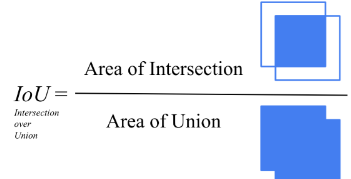